In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [100]:
import os
train_labels=os.listdir('/content/drive/MyDrive/images/train')
test_labels=os.listdir('/content/drive/MyDrive/images/test')
print(train_labels)
print(test_labels)

['cat', 'dog']
['cat', 'dog']


In [84]:
import os

bike_test_dir = '/content/image dataset/test/cat'

# Check if the directory exists
if not os.path.exists(bike_test_dir):
    print(f"Directory not found: {bike_test_dir}")
else:
    files = os.listdir(bike_test_dir)
    bike_files = [f for f in files if os.path.isfile(os.path.join(bike_test_dir, f))]

    print(f"Found {len(bike_files)} files in '{bike_test_dir}'.")

    # Rename files
    for i, filename in enumerate(bike_files):
        old_path = os.path.join(bike_test_dir, filename)
        name, ext = os.path.splitext(filename)
        new_filename = f"dog_image_{i+1:3d}{ext}" # e.g., bike_image_001.jpg
        new_path = os.path.join(bike_test_dir, new_filename)

        try:
            os.rename(old_path, new_path)
            print(f"Renamed '{filename}' to '{new_filename}'")
        except Exception as e:
            print(f"Error renaming '{filename}': {e}")
    print("All dog images in the Train folder have been renamed.")


Found 10 files in '/content/image dataset/test/cat'.
Renamed 'cat_image_023 - Copy (10).jpg' to 'dog_image_  1.jpg'
Renamed 'cat_image_023 - Copy (7).jpg' to 'dog_image_  2.jpg'
Renamed 'cat_image_023 - Copy (4).jpg' to 'dog_image_  3.jpg'
Renamed 'cat_image_023 - Copy (11).jpg' to 'dog_image_  4.jpg'
Renamed 'cat_image_023 - Copy (6).jpg' to 'dog_image_  5.jpg'
Renamed 'cat_image_023 - Copy (3).jpg' to 'dog_image_  6.jpg'
Renamed 'cat_image_023 - Copy (2).jpg' to 'dog_image_  7.jpg'
Renamed 'cat_image_023 - Copy (9).jpg' to 'dog_image_  8.jpg'
Renamed 'cat_image_023 - Copy (8).jpg' to 'dog_image_  9.jpg'
Renamed 'cat_image_023 - Copy (5).jpg' to 'dog_image_ 10.jpg'
All dog images in the Train folder have been renamed.


In [ ]:
import os
import random
import shutil

# Define the base path for your Drive folder
base_path = '/content/drive/MyDrive/images'
train_path = os.path.join(base_path, 'train')
test_path = os.path.join(base_path, 'test')

# The two classes
classes = ['cat', 'dog']

for cls in classes:
    # Source and destination paths
    src_dir = os.path.join(train_path, cls)
    dst_dir = os.path.join(test_path, cls)

    # Get list of all images in the train class folder
    all_images = [f for f in os.listdir(src_dir) if os.path.isfile(os.path.join(src_dir, f))]

    # Calculate 20% of the total images
    num_to_move = int(len(all_images) * 0.20)

    # Randomly select the images to move
    images_to_move = random.seed(42)
    images_to_move = random.sample(all_images, num_to_move)

    # Move each selected image to the corresponding test folder
    for img in images_to_move:
        shutil.move(os.path.join(src_dir, img), os.path.join(dst_dir, img))

    print(f"Moved {num_to_move} images from train/{cls} to test/{cls}")


Moved 80 images from train/cat to test/cat
Moved 80 images from train/dog to test/dog


In [101]:
from tensorflow.keras.preprocessing import image_dataset_from_directory
import os
base_dir=r'/content/drive/MyDrive/images'
train_dir=os.path.join(base_dir,'train')
test_dir=os.path.join(base_dir,'test')
train_datagen=image_dataset_from_directory(train_dir,image_size=(200,200),

                                           seed=1,

                                           batch_size=32)

test_datagen=image_dataset_from_directory(test_dir,image_size=(200,200),

                                           seed=1,

                                           batch_size=32)


Found 395 files belonging to 2 classes.
Found 160 files belonging to 2 classes.


In [102]:
import tensorflow as tf
from tensorflow import keras
from keras import layers
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Activation,Dropout,Flatten,Dense
from tensorflow.keras.layers import Conv2D,MaxPooling2D

model=tf.keras.models.Sequential([
    layers.Conv2D(32,(3,3),activation='relu',input_shape=(200,200,3)),
#input layer, #convolution layer (32)
#relu == regression linear unit
    #input shape == 200,200,3(rgb)

    layers.MaxPooling2D(2,2),


    layers.Flatten(),
    layers.Dense(512,activation='relu'), #hidden layer
    layers.Dense(512,activation='relu'), #hidden layer
    layers.Dense(512,activation='relu'), #hidden layer


    layers.Dense(1,activation='sigmoid') #output sigmoid === binary  (dog,cat) #softmax (multi)
])

In [103]:
model.compile(optimizer='adam',loss='binary_crossentropy',metrics=['accuracy'])

In [104]:
model.fit(train_datagen,validation_data=test_datagen,batch_size=32,epochs=30)


Epoch 1/30
13/13 ━━━━━━━━━━━━━━━━━━━━ 21s 1s/step - accuracy: 0.6436 - loss: 2810.5303 - val_accuracy: 0.6375 - val_loss: 1043.7164
Epoch 2/30
13/13 ━━━━━━━━━━━━━━━━━━━━ 14s 1s/step - accuracy: 0.8765 - loss: 79.0068 - val_accuracy: 0.7750 - val_loss: 1045.1321
Epoch 3/30
13/13 ━━━━━━━━━━━━━━━━━━━━ 14s 1s/step - accuracy: 1.0000 - loss: 0.0000e+00 - val_accuracy: 0.7750 - val_loss: 2018.0989
Epoch 4/30
13/13 ━━━━━━━━━━━━━━━━━━━━ 19s 938ms/step - accuracy: 0.9431 - loss: 9.7048 - val_accuracy: 0.7750 - val_loss: 1147.5460
Epoch 5/30
13/13 ━━━━━━━━━━━━━━━━━━━━ 13s 945ms/step - accuracy: 0.9945 - loss: 0.3468 - val_accuracy: 0.7750 - val_loss: 1576.4670
Epoch 6/30
13/13 ━━━━━━━━━━━━━━━━━━━━ 21s 998ms/step - accuracy: 0.9817 - loss: 21.9234 - val_accuracy: 0.7750 - val_loss: 4020.2727
Epoch 7/30
13/13 ━━━━━━━━━━━━━━━━━━━━ 13s 1s/step - accuracy: 0.9567 - loss: 98.5114 - val_accuracy: 0.7937 - val_loss: 1772.2393
Epoch 8/30
13/13 ━━━━━━━━━━━━━━━━━━━━ 12s 962ms/step - accuracy: 1.0000 - loss

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 65ms/step
[[0.]]
cat


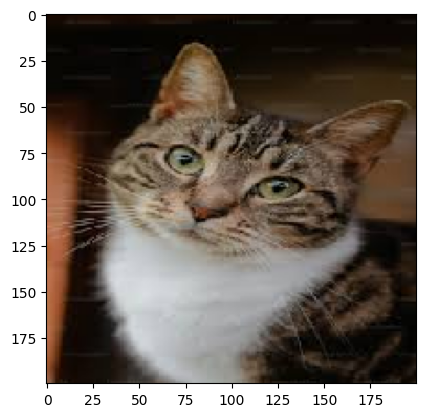

In [115]:
from keras.preprocessing import image
import numpy as np
#Input image
test_image = image.load_img(r'/content/drive/MyDrive/images/test/cat/cat_image_001.jpg',target_size=(200,200))
#For show image
from matplotlib import pyplot as plt

plt.imshow(test_image)
test_image = image.img_to_array(test_image)
test_image = np.expand_dims(test_image,axis=0)
result = model.predict(test_image)
print(result)
#Mapping result array with the main name list
if result[0][0] < 0.5:
    print("cat")
else:
  print("dog")

In [78]:
# Dataset setup:
# Extract your dataset archive manually in Google Colab or place the extracted folder
# at the dataset path used in the following cells.

Archive:  /content/image_dataset.zip
   creating: image dataset/
   creating: image dataset/test/
   creating: image dataset/test/cat/
  inflating: image dataset/test/cat/cat_image_023 - Copy (10).jpg  
  inflating: image dataset/test/cat/cat_image_023 - Copy (11).jpg  
  inflating: image dataset/test/cat/cat_image_023 - Copy (2).jpg  
  inflating: image dataset/test/cat/cat_image_023 - Copy (3).jpg  
  inflating: image dataset/test/cat/cat_image_023 - Copy (4).jpg  
  inflating: image dataset/test/cat/cat_image_023 - Copy (5).jpg  
  inflating: image dataset/test/cat/cat_image_023 - Copy (6).jpg  
  inflating: image dataset/test/cat/cat_image_023 - Copy (7).jpg  
  inflating: image dataset/test/cat/cat_image_023 - Copy (8).jpg  
  inflating: image dataset/test/cat/cat_image_023 - Copy (9).jpg  
   creating: image dataset/test/dog/
  inflating: image dataset/test/dog/dog_image_212 - Copy (10).jpg  
  inflating: image dataset/test/dog/dog_image_212 - Copy (11).jpg  
  inflating: image d

### Dataset and execution notes
- Update dataset paths to match the folders available in your environment before running.
- The original CNN architecture and training workflow have been retained.
- Results depend on dataset quality, class balance, folder order, and training configuration.